# Notebook 09 — Validação externa no PulseDB CalBased Test

**Projeto de Iniciação Científica PIBIC — PUC-SP**
**Aluna:** Letícia Barboza de Godoi
**Orientador:** Prof. Dr. Renan Trevisoli Doria
**Curso:** Engenharia Biomédica

---

## Contexto e motivação

Este notebook implementa a validação externa **principal** do trabalho, aplicando os modelos da Versão C (35 features invariantes) ao subset **CalBased Test** do PulseDB. Este é o cenário mais rigoroso e defensável para publicação, pois:

1. **É o subset oficial** para avaliação de métodos *calibration-based* no benchmark estabelecido por Wang et al. (2023).
2. **Possui 51.720 segmentos de 1.293 sujeitos**, oferecendo poder estatístico muito superior ao AAMI Test (666 segmentos / 116 sujeitos) usado nos NB07-08.
3. **Permite comparação direta** com o paper original do PulseDB e com qualquer trabalho futuro que use o mesmo benchmark.

## Estratégia de calibração

Para cada sujeito do CalBased Test:
- **Primeiros 5 segmentos** → utilizados como referência de calibração (ajuste de regressão linear `y_real = a · y_pred + b`)
- **Demais segmentos** (~35 em média) → avaliação do modelo calibrado

A escolha de 5 segmentos de calibração reflete:
- Conformidade com recomendações dos padrões AAMI/ISO 81060-2 e BHS, que pedem múltiplas medições de referência
- Realismo clínico: simula o paciente realizando 5 medições iniciais com braçadeira antes de utilizar o sensor PPG continuamente
- Demonstração de eficiência: bons resultados com apenas 5 segmentos têm valor de publicação superior

## Diferenças em relação aos notebooks anteriores

| Aspecto | NB08 (AAMI Test) | NB09 (CalBased Test) |
|---|---|---|
| Subset | AAMI Test | **CalBased Test** ⭐ |
| Sujeitos | 116 | **1.293** |
| Segmentos | 666 | **51.720** |
| Split de calibração | Inventado (50/50) | **Padrão de literatura (5 cal + resto teste)** |
| Comparabilidade com baseline | Limitada | **Direta com Wang et al. (2023)** |
| Tempo de execução | ~30s | ~15-20 min |

---


## 1. Importações e configuração

In [1]:
import os
import json
import socket
import warnings
from pathlib import Path
from datetime import datetime

import numpy as np
import pandas as pd
import mat73
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt, find_peaks
from scipy.stats import skew, kurtosis

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.facecolor"] = "white"
plt.rcParams["savefig.facecolor"] = "white"
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["figure.dpi"] = 100

print("Computador:", socket.gethostname())
print("Inicio:", datetime.now().strftime("%d/%m/%Y %H:%M:%S"))

Computador: NtebookLeticia
Inicio: 09/06/2026 19:25:00


In [2]:
# Caminhos
BASE_IC = Path(r"C:\IC_PPG")
PASTA_DADOS = BASE_IC / "Datasets" / "PTT_PPG"
PASTA_MODELO = BASE_IC / "Modelos_Salvos" / "PTT_PPG"
PASTA_PULSEDB_FEAT = BASE_IC / "Datasets" / "PulseDB_features"
PASTA_FIGS = BASE_IC / "Figuras_Geradas"
PASTA_PULSEDB_FEAT.mkdir(parents=True, exist_ok=True)

arquivo_calbased = (BASE_IC / "Datasets" / "PulseDB_Kaggle" / "datasets" /
                    "weinanwangrutgers" / "pulsedb-balanced-training-and-testing" /
                    "versions" / "4" / "VitalDB_CalBased_Test_Subset.mat")

# Arquivos do pipeline existente
arquivos = {
    "CalBased Test (.mat)":      arquivo_calbased,
    "Modelo PAS vC (.joblib)":   PASTA_MODELO / "rf_sys_vC.joblib",
    "Modelo PAD vC (.joblib)":   PASTA_MODELO / "rf_dia_vC.joblib",
    "Configuracoes (.json)":     PASTA_DADOS / "_configuracoes_modelos.json",
    "Classificacao features":    PASTA_DADOS / "_features_classificacao.csv",
}

print("Verificacao dos arquivos:")
for nome, caminho in arquivos.items():
    if caminho.exists():
        tam_mb = caminho.stat().st_size / (1024**2)
        print(f"  OK    {nome:<28} {tam_mb:>9.2f} MB")
    else:
        raise FileNotFoundError(f"Faltando: {caminho}")

Verificacao dos arquivos:
  OK    CalBased Test (.mat)           1461.64 MB
  OK    Modelo PAS vC (.joblib)         112.43 MB
  OK    Modelo PAD vC (.joblib)         112.21 MB
  OK    Configuracoes (.json)             0.00 MB
  OK    Classificacao features            0.00 MB


## 2. Parâmetros do pipeline

Mantêm-se exatamente os mesmos parâmetros do NB07 V2.


In [3]:
# Parametros de processamento (identicos NB07 V2)
FS = 125
DURACAO_SEGMENTO = 10
N_AMOSTRAS = FS * DURACAO_SEGMENTO

FREQ_CORTE_INF = 0.5
FREQ_CORTE_SUP = 8.0
ORDEM_FILTRO = 4

FC_MAXIMA_BPM = 200
DISTANCIA_MINIMA_S = 60.0 / FC_MAXIMA_BPM
DISTANCIA_MINIMA_AMOSTRAS = int(DISTANCIA_MINIMA_S * FS)

NIVEIS_LARGURA = [10, 25, 33, 50, 66, 75]

# Parametro especifico deste notebook
N_SEGMENTOS_CALIBRACAO = 5  # primeiros segmentos de cada sujeito para calibrar
N_MIN_SEG_TESTE = 5         # minimo de segmentos de teste por sujeito

print(f"FS = {FS} Hz")
print(f"Segmentos de calibracao por sujeito: {N_SEGMENTOS_CALIBRACAO}")
print(f"Minimo de segmentos de teste por sujeito: {N_MIN_SEG_TESTE}")

FS = 125 Hz
Segmentos de calibracao por sujeito: 5
Minimo de segmentos de teste por sujeito: 5


## 3. Funções de processamento

Funções idênticas às do NB07 V2 (que reproduz fielmente `extract_pulse_features_v2` do NB02).


In [4]:
def projetar_filtro_butterworth(fs, freq_inf, freq_sup, ordem):
    nyquist = fs / 2.0
    return butter(ordem, [freq_inf/nyquist, freq_sup/nyquist], btype="band")


def aplicar_filtro_bidirecional(sinal, b, a):
    return filtfilt(b, a, sinal)


def detectar_picos_sistolicos(ppg_filtrado, distancia_minima):
    altura_min = np.median(ppg_filtrado) + 0.3 * (
        np.max(ppg_filtrado) - np.median(ppg_filtrado)
    )
    indices, _ = find_peaks(ppg_filtrado, distance=distancia_minima, height=altura_min)
    return indices


def extrair_features_ciclo(ppg_segmento, fs):
    """Replica fielmente extract_pulse_features_v2 do NB02 (versao validada)."""
    n = len(ppg_segmento)
    duracao_s = n / fs

    if n < int(0.33 * fs) or duracao_s > 2.0:
        return None

    seg_min = ppg_segmento.min()
    seg_max = ppg_segmento.max()
    seg_range = seg_max - seg_min

    if seg_range < 1e-10:
        return None

    seg_norm = (ppg_segmento - seg_min) / seg_range
    feats = {}

    # Temporais
    feats["cardiac_period_s"] = duracao_s
    feats["heart_rate_bpm"] = 60.0 / duracao_s
    peak_idx = int(np.argmax(seg_norm))
    sut = peak_idx / fs
    dt = (n - peak_idx) / fs
    feats["systolic_upstroke_time_s"] = sut
    feats["diastolic_time_s"] = dt
    feats["sut_dt_ratio"] = sut / dt if dt > 0.02 else np.nan

    # Larguras
    for pct in NIVEIS_LARGURA:
        threshold = pct / 100.0
        above = seg_norm >= threshold
        if above.sum() > 0:
            indices = np.where(above)[0]
            total_w = (indices[-1] - indices[0]) / fs
            sys_idx = indices[indices <= peak_idx]
            dia_idx = indices[indices > peak_idx]
            sw = (sys_idx[-1] - sys_idx[0]) / fs if len(sys_idx) > 1 else 0.0
            dw = (dia_idx[-1] - dia_idx[0]) / fs if len(dia_idx) > 1 else 0.0
            feats[f"w{pct}_total"] = total_w
            feats[f"w{pct}_sys"] = sw
            feats[f"w{pct}_dia"] = dw
            feats[f"w{pct}_ratio"] = dw / sw if sw > 0.005 else np.nan
        else:
            feats[f"w{pct}_total"] = 0.0
            feats[f"w{pct}_sys"] = 0.0
            feats[f"w{pct}_dia"] = 0.0
            feats[f"w{pct}_ratio"] = np.nan

    # Amplitude
    feats["amplitude"] = float(seg_max - seg_min)
    feats["peak_value"] = float(seg_max)
    feats["valley_value"] = float(seg_min)
    if abs(seg_min) > 1e-9:
        feats["crest_factor"] = float(seg_max / abs(seg_min))
    else:
        feats["crest_factor"] = float(seg_max / 1e-9)

    # Estatisticas
    feats["variance"] = float(np.var(ppg_segmento))
    feats["std"] = float(np.std(ppg_segmento))
    feats["skewness"] = float(skew(seg_norm))
    feats["kurtosis"] = float(kurtosis(seg_norm, fisher=True))
    feats["auc"] = float(np.trapz(seg_norm) / fs)

    # Hjorth
    activity = float(np.var(ppg_segmento))
    diff1 = np.diff(ppg_segmento)
    diff2 = np.diff(diff1)
    mobility = float(np.sqrt(np.var(diff1) / activity)) if activity > 1e-12 else np.nan
    var_d1 = float(np.var(diff1))
    if var_d1 > 1e-12 and not np.isnan(mobility) and mobility > 1e-12:
        complexity = float((np.sqrt(np.var(diff2) / var_d1)) / mobility)
    else:
        complexity = np.nan
    feats["hjorth_activity"] = activity
    feats["hjorth_mobility"] = mobility
    feats["hjorth_complexity"] = complexity

    return feats


coef_b, coef_a = projetar_filtro_butterworth(FS, FREQ_CORTE_INF, FREQ_CORTE_SUP, ORDEM_FILTRO)
print("Funcoes prontas.")

Funcoes prontas.


## 4. Carregamento e definição dos splits Cal/Test

Carrega o arquivo `.mat` do CalBased Test e, para cada sujeito, marca os 5 primeiros segmentos como **Cal** e os demais como **Test**.


In [5]:
print(f"Carregando {arquivo_calbased.name}...")
print(f"Tamanho: {arquivo_calbased.stat().st_size / (1024**3):.2f} GB")
print(f"(pode demorar 30-90 segundos)")

inicio = datetime.now()
dados = mat73.loadmat(str(arquivo_calbased))
subset = dados["Subset"]
duracao = (datetime.now() - inicio).total_seconds()
print(f"Carregado em {duracao:.1f} s")

n_segmentos = subset["Signals"].shape[0]
print(f"\nTotal de segmentos: {n_segmentos}")
print(f"Total de sujeitos:   {len(set(s[0] for s in subset['Subject']))}")

Carregando VitalDB_CalBased_Test_Subset.mat...
Tamanho: 1.43 GB
(pode demorar 30-90 segundos)
Carregado em 95.5 s

Total de segmentos: 51720
Total de sujeitos:   1293


In [6]:
# Define splits Cal/Test por sujeito
print("Definindo splits Cal/Test...")

# Mapeia segmento -> sujeito
sujeitos_por_segmento = [s[0] for s in subset["Subject"]]

# Para cada sujeito, conta segmentos e atribui Cal/Test pela ordem
contagem_por_sujeito = {}
split_por_segmento = np.empty(n_segmentos, dtype="<U10")  # "Cal" ou "Test"

for idx_seg in range(n_segmentos):
    subj = sujeitos_por_segmento[idx_seg]
    n_visto = contagem_por_sujeito.get(subj, 0)
    if n_visto < N_SEGMENTOS_CALIBRACAO:
        split_por_segmento[idx_seg] = "Cal"
    else:
        split_por_segmento[idx_seg] = "Test"
    contagem_por_sujeito[subj] = n_visto + 1

# Estatisticas
n_cal = (split_por_segmento == "Cal").sum()
n_test = (split_por_segmento == "Test").sum()
print(f"\nSegmentos de CALIBRACAO:  {n_cal:>6}  ({100*n_cal/n_segmentos:5.1f}%)")
print(f"Segmentos de TESTE:        {n_test:>6}  ({100*n_test/n_segmentos:5.1f}%)")

# Sujeitos com pelo menos N_MIN_SEG_TESTE segmentos de teste
import collections
ct_por_subj = collections.Counter(sujeitos_por_segmento)
sujeitos_validos = [s for s, c in ct_por_subj.items()
                    if c >= N_SEGMENTOS_CALIBRACAO + N_MIN_SEG_TESTE]
sujeitos_excluidos = [s for s, c in ct_por_subj.items()
                      if c < N_SEGMENTOS_CALIBRACAO + N_MIN_SEG_TESTE]

print(f"\nSujeitos com {N_SEGMENTOS_CALIBRACAO}+{N_MIN_SEG_TESTE} segmentos minimos: {len(sujeitos_validos)}")
print(f"Sujeitos excluidos (poucos segmentos): {len(sujeitos_excluidos)}")

# Marca segmentos de sujeitos excluidos
mask_sujeito_valido = np.array([s in sujeitos_validos for s in sujeitos_por_segmento])
print(f"\nSegmentos uteis (de sujeitos validos): {mask_sujeito_valido.sum()}")

Definindo splits Cal/Test...

Segmentos de CALIBRACAO:    6465  ( 12.5%)
Segmentos de TESTE:         45255  ( 87.5%)

Sujeitos com 5+5 segmentos minimos: 1293
Sujeitos excluidos (poucos segmentos): 0

Segmentos uteis (de sujeitos validos): 51720


## 5. Extração de features (51.720 segmentos)

Aplica o pipeline (filtragem → detecção de picos → extração de features) em todos os segmentos. Esta é a etapa mais demorada do notebook (~10-15 min). O progresso é mostrado a cada 5.000 segmentos.


In [7]:
print("Iniciando extracao de features...")
print(f"Total a processar: {n_segmentos} segmentos")
print(f"Tempo estimado: 10-15 minutos")
print()

inicio_total = datetime.now()
linhas_features = []
problemas = {"sem_picos": 0, "ciclo_invalido": 0, "sujeito_excluido": 0}

for idx_seg in range(n_segmentos):
    # Pula segmentos de sujeitos com poucos dados
    if not mask_sujeito_valido[idx_seg]:
        problemas["sujeito_excluido"] += 1
        continue

    ppg_bruto = subset["Signals"][idx_seg, 1, :]
    ppg_filt = aplicar_filtro_bidirecional(ppg_bruto, coef_b, coef_a)
    indices_picos = detectar_picos_sistolicos(ppg_filt, DISTANCIA_MINIMA_AMOSTRAS)

    if len(indices_picos) < 2:
        problemas["sem_picos"] += 1
        continue

    # Metadados
    sbp_seg = float(subset["SBP"][idx_seg])
    dbp_seg = float(subset["DBP"][idx_seg])
    subj_raw = subset["Subject"][idx_seg]
    subject_id = f"v{subj_raw[0]}" if isinstance(subj_raw, list) else f"v{subj_raw}"
    gen_raw = subset["Gender"][idx_seg]
    genero = str(gen_raw[0]) if isinstance(gen_raw, list) else str(gen_raw)
    idade = float(subset["Age"][idx_seg])
    altura = float(subset["Height"][idx_seg])
    peso = float(subset["Weight"][idx_seg])
    split_seg = split_por_segmento[idx_seg]

    # Itera entre picos consecutivos
    for i in range(len(indices_picos) - 1):
        ini = indices_picos[i]
        fim = indices_picos[i+1]
        ciclo = ppg_filt[ini:fim]

        feats = extrair_features_ciclo(ciclo, FS)
        if feats is None:
            problemas["ciclo_invalido"] += 1
            continue

        feats["record"] = f"seg_{idx_seg:05d}"
        feats["subject"] = subject_id
        feats["condition"] = "rest"
        feats["cycle_idx"] = i
        feats["peak_sample"] = int(ini)
        feats["time_s"] = float(ini / FS)
        feats["bp_sys_start"] = sbp_seg
        feats["bp_sys_end"] = sbp_seg
        feats["bp_dia_start"] = dbp_seg
        feats["bp_dia_end"] = dbp_seg
        feats["bp_sys_mean"] = sbp_seg
        feats["bp_dia_mean"] = dbp_seg
        feats["age"] = idade
        feats["gender"] = genero
        feats["height"] = altura
        feats["weight"] = peso
        feats["split"] = split_seg  # NOVO: Cal ou Test

        linhas_features.append(feats)

    if (idx_seg + 1) % 5000 == 0:
        decorrido = (datetime.now() - inicio_total).total_seconds()
        velocidade = (idx_seg + 1) / decorrido
        eta = (n_segmentos - idx_seg - 1) / velocidade
        print(f"  {idx_seg+1}/{n_segmentos} segmentos | "
              f"{len(linhas_features)} ciclos | "
              f"{decorrido:.0f}s decorridos | "
              f"ETA: {eta:.0f}s ({eta/60:.1f} min)")

duracao_total = (datetime.now() - inicio_total).total_seconds()
print()
print("=" * 60)
print(f"EXTRACAO CONCLUIDA em {duracao_total:.1f} s ({duracao_total/60:.1f} min)")
print(f"Ciclos extraidos:           {len(linhas_features)}")
print(f"Segmentos sem picos:        {problemas['sem_picos']}")
print(f"Ciclos invalidos:           {problemas['ciclo_invalido']}")
print(f"Segmentos sujeito excluido: {problemas['sujeito_excluido']}")

Iniciando extracao de features...
Total a processar: 51720 segmentos
Tempo estimado: 10-15 minutos

  5000/51720 segmentos | 54450 ciclos | 132s decorridos | ETA: 1231s (20.5 min)
  10000/51720 segmentos | 110433 ciclos | 277s decorridos | ETA: 1157s (19.3 min)
  15000/51720 segmentos | 168168 ciclos | 430s decorridos | ETA: 1053s (17.5 min)
  20000/51720 segmentos | 224121 ciclos | 562s decorridos | ETA: 892s (14.9 min)
  25000/51720 segmentos | 280344 ciclos | 701s decorridos | ETA: 749s (12.5 min)
  30000/51720 segmentos | 334824 ciclos | 838s decorridos | ETA: 607s (10.1 min)
  35000/51720 segmentos | 389939 ciclos | 980s decorridos | ETA: 468s (7.8 min)
  40000/51720 segmentos | 444579 ciclos | 1122s decorridos | ETA: 329s (5.5 min)
  45000/51720 segmentos | 499946 ciclos | 1265s decorridos | ETA: 189s (3.1 min)
  50000/51720 segmentos | 554171 ciclos | 1405s decorridos | ETA: 48s (0.8 min)

EXTRACAO CONCLUIDA em 1453.1 s (24.2 min)
Ciclos extraidos:           573758
Segmentos sem

In [8]:
# Constroi DataFrame
df_calbased = pd.DataFrame(linhas_features)
print(f"DataFrame: {df_calbased.shape[0]} ciclos x {df_calbased.shape[1]} colunas")
print()
print("Distribuicao por split:")
print(df_calbased["split"].value_counts().to_string())
print()
print(f"Sujeitos com dados: {df_calbased['subject'].nunique()}")
print(f"SBP: {df_calbased['bp_sys_mean'].min():.1f} - {df_calbased['bp_sys_mean'].max():.1f} mmHg")
print(f"DBP: {df_calbased['bp_dia_mean'].min():.1f} - {df_calbased['bp_dia_mean'].max():.1f} mmHg")

DataFrame: 573758 ciclos x 58 colunas

Distribuicao por split:
split
Test    503667
Cal      70091

Sujeitos com dados: 1293
SBP: 46.6 - 248.5 mmHg
DBP: 22.5 - 241.0 mmHg


In [9]:
# Imputacao de NaN (mesma estrategia NB05/07)
META_COLS = ["record", "subject", "condition", "cycle_idx", "peak_sample", "time_s",
             "bp_sys_start", "bp_sys_end", "bp_dia_start", "bp_dia_end",
             "age", "gender", "height", "weight", "split"]
TARGET_COLS = ["bp_sys_mean", "bp_dia_mean"]
features_cols = [c for c in df_calbased.columns if c not in META_COLS + TARGET_COLS]
print(f"Features morfologicas: {len(features_cols)} (esperado: 41)")
assert len(features_cols) == 41

# Conta NaN antes
nan_antes = df_calbased[features_cols].isna().sum().sum()
print(f"\nTotal de NaN antes da imputacao: {nan_antes}")

# Imputa: mediana por sujeito -> mediana global
for col in features_cols:
    if df_calbased[col].isna().any():
        df_calbased[col] = df_calbased.groupby("subject")[col].transform(
            lambda x: x.fillna(x.median())
        )
        if df_calbased[col].isna().any():
            df_calbased[col] = df_calbased[col].fillna(df_calbased[col].median())

nan_depois = df_calbased[features_cols].isna().sum().sum()
print(f"NaN apos imputacao: {nan_depois}")
assert nan_depois == 0

Features morfologicas: 41 (esperado: 41)

Total de NaN antes da imputacao: 2198986
NaN apos imputacao: 0


## 6. Aplicação dos modelos da Versão C

In [10]:
# Carrega configuracoes e modelos
with open(PASTA_DADOS / "_configuracoes_modelos.json", "r", encoding="utf-8") as f:
    configs = json.load(f)
FEATURES_VC = configs["C"]["features"]
print(f"Versao C: {len(FEATURES_VC)} features")
assert len(FEATURES_VC) == 35

rf_sys = joblib.load(PASTA_MODELO / "rf_sys_vC.joblib")
rf_dia = joblib.load(PASTA_MODELO / "rf_dia_vC.joblib")
print(f"Modelos carregados: rf_sys (n_features={rf_sys.n_features_in_}), "
      f"rf_dia (n_features={rf_dia.n_features_in_})")

# Aplica
X = df_calbased[FEATURES_VC].values.astype(np.float32)
print(f"\nAplicando modelos em {len(X)} ciclos...")
inicio = datetime.now()
y_sys_pred = rf_sys.predict(X)
y_dia_pred = rf_dia.predict(X)
print(f"Predicao concluida em {(datetime.now()-inicio).total_seconds():.1f} s")

df_calbased["y_sys_pred"] = y_sys_pred
df_calbased["y_dia_pred"] = y_dia_pred

Versao C: 35 features
Modelos carregados: rf_sys (n_features=35), rf_dia (n_features=35)

Aplicando modelos em 573758 ciclos...
Predicao concluida em 4.9 s


## 7. Calibração linear por sujeito (Cal → Test)

Para cada sujeito, ajusta `y_real = a · y_pred + b` usando os 5 segmentos marcados como **Cal**, e aplica essa transformação nos segmentos **Test**. Apenas os ciclos com `split == "Test"` serão usados na avaliação final.


In [11]:
y_sys_pred_cal = np.full(len(df_calbased), np.nan)
y_dia_pred_cal = np.full(len(df_calbased), np.nan)

split_arr = df_calbased["split"].values
subj_arr = df_calbased["subject"].values
y_sys_real = df_calbased["bp_sys_mean"].values
y_dia_real = df_calbased["bp_dia_mean"].values

sujeitos_unicos = sorted(np.unique(subj_arr))
n_calibrados = 0
n_sem_cal_suficiente = 0

print(f"Calibrando {len(sujeitos_unicos)} sujeitos...")
inicio = datetime.now()

for subj in sujeitos_unicos:
    mask_subj = (subj_arr == subj)
    mask_cal = mask_subj & (split_arr == "Cal")
    mask_test = mask_subj & (split_arr == "Test")

    # Garante minimo de pontos para regressao
    if mask_cal.sum() < 10:  # pelo menos 10 ciclos (~2 segmentos com batimentos)
        n_sem_cal_suficiente += 1
        continue

    # Calibra PAS
    reg_sys = LinearRegression()
    reg_sys.fit(y_sys_pred[mask_cal].reshape(-1, 1), y_sys_real[mask_cal])
    y_sys_pred_cal[mask_test] = reg_sys.predict(y_sys_pred[mask_test].reshape(-1, 1))

    # Calibra PAD
    reg_dia = LinearRegression()
    reg_dia.fit(y_dia_pred[mask_cal].reshape(-1, 1), y_dia_real[mask_cal])
    y_dia_pred_cal[mask_test] = reg_dia.predict(y_dia_pred[mask_test].reshape(-1, 1))

    n_calibrados += 1

duracao = (datetime.now() - inicio).total_seconds()
print(f"Calibracao concluida em {duracao:.1f} s")
print(f"\nSujeitos calibrados:         {n_calibrados}")
print(f"Sujeitos sem ciclos cal:    {n_sem_cal_suficiente}")

# Mascara de ciclos efetivamente avaliados
mask_avaliacao = ~np.isnan(y_sys_pred_cal) & (split_arr == "Test")
print(f"\nCiclos de teste calibrados: {mask_avaliacao.sum()}")

df_calbased["y_sys_pred_cal"] = y_sys_pred_cal
df_calbased["y_dia_pred_cal"] = y_dia_pred_cal

Calibrando 1293 sujeitos...
Calibracao concluida em 435.0 s

Sujeitos calibrados:         1293
Sujeitos sem ciclos cal:    0

Ciclos de teste calibrados: 503667


## 8. Cálculo das métricas

Calcula MAE, RMSE, R², ME, SD e classificações BHS/AAMI **apenas nos ciclos de teste calibrados** (cenário oficial calibration-based).


In [12]:
def metricas_completas(y_real, y_pred):
    if len(y_real) == 0:
        return {"MAE":np.nan,"RMSE":np.nan,"R2":np.nan,"ME":np.nan,"SD":np.nan,
                "pct_5":np.nan,"pct_10":np.nan,"pct_15":np.nan,"n":0}
    erros = y_real - y_pred
    abs_erros = np.abs(erros)
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan,
        "ME": float(np.mean(erros)),
        "SD": float(np.std(erros, ddof=1)) if len(erros) > 1 else 0.0,
        "pct_5": 100 * float(np.mean(abs_erros <= 5)),
        "pct_10": 100 * float(np.mean(abs_erros <= 10)),
        "pct_15": 100 * float(np.mean(abs_erros <= 15)),
        "n": int(len(y_real)),
    }


def classificar_bhs(p5, p10, p15):
    if p5 >= 60 and p10 >= 85 and p15 >= 95: return "A"
    if p5 >= 50 and p10 >= 75 and p15 >= 90: return "B"
    if p5 >= 40 and p10 >= 65 and p15 >= 85: return "C"
    return "D"


def classificar_aami(me, sd):
    return "PASSA" if (abs(me) <= 5 and sd <= 8) else "FALHA"


# PAS
m_sys = metricas_completas(y_sys_real[mask_avaliacao], y_sys_pred_cal[mask_avaliacao])
bhs_sys = classificar_bhs(m_sys["pct_5"], m_sys["pct_10"], m_sys["pct_15"])
aami_sys = classificar_aami(m_sys["ME"], m_sys["SD"])

# PAD
m_dia = metricas_completas(y_dia_real[mask_avaliacao], y_dia_pred_cal[mask_avaliacao])
bhs_dia = classificar_bhs(m_dia["pct_5"], m_dia["pct_10"], m_dia["pct_15"])
aami_dia = classificar_aami(m_dia["ME"], m_dia["SD"])

print("RESULTADO PRINCIPAL — VALIDACAO EXTERNA NO PULSEDB CALBASED TEST")
print("=" * 80)
print()
print(f"Configuracao: 5 segmentos de calibracao por sujeito, demais para teste")
print(f"Modelo: Versao C (35 features invariantes) treinado no PTT-PPG")
print()
print(f"{'':<8} {'n':>7} {'MAE':>8} {'RMSE':>8} {'R2':>8} "
      f"{'ME':>8} {'SD':>8} {'pct<=5':>8} {'pct<=10':>9} {'pct<=15':>9} "
      f"{'BHS':>4} {'AAMI':>6}")
print("-" * 80)
print(f"PAS      {m_sys['n']:>7} {m_sys['MAE']:>8.2f} {m_sys['RMSE']:>8.2f} "
      f"{m_sys['R2']:>8.3f} {m_sys['ME']:>8.2f} {m_sys['SD']:>8.2f} "
      f"{m_sys['pct_5']:>8.1f} {m_sys['pct_10']:>9.1f} {m_sys['pct_15']:>9.1f} "
      f"{bhs_sys:>4} {aami_sys:>6}")
print(f"PAD      {m_dia['n']:>7} {m_dia['MAE']:>8.2f} {m_dia['RMSE']:>8.2f} "
      f"{m_dia['R2']:>8.3f} {m_dia['ME']:>8.2f} {m_dia['SD']:>8.2f} "
      f"{m_dia['pct_5']:>8.1f} {m_dia['pct_10']:>9.1f} {m_dia['pct_15']:>9.1f} "
      f"{bhs_dia:>4} {aami_dia:>6}")

RESULTADO PRINCIPAL — VALIDACAO EXTERNA NO PULSEDB CALBASED TEST

Configuracao: 5 segmentos de calibracao por sujeito, demais para teste
Modelo: Versao C (35 features invariantes) treinado no PTT-PPG

               n      MAE     RMSE       R2       ME       SD   pct<=5   pct<=10   pct<=15  BHS   AAMI
--------------------------------------------------------------------------------
PAS       503667    15.71    20.63   -0.206     0.75    20.61     22.0      41.8      58.1    D  FALHA
PAD       503667     8.77    11.62    0.059     0.72    11.59     38.2      65.9      82.8    D  FALHA


In [13]:
# Comparacao com os outros resultados ja obtidos
print()
print("COMPARACAO COM RESULTADOS ANTERIORES")
print("=" * 80)
print()
print(f"{'Cenario':<35} {'MAE PAS':>10} {'MAE PAD':>10} {'BHS PAS':>9} {'BHS PAD':>9}")
print("-" * 80)
print(f"{'PTT-PPG (NB05, baseline)':<35} {'3.63':>10} {'3.08':>10} {'A':>9} {'A':>9}")
print(f"{'PulseDB AAMI Test (NB08)':<35} {'14.28':>10} {'8.32':>10} {'D':>9} {'D':>9}")
print(f"{'PulseDB CalBased (NB09 - este)':<35} {m_sys['MAE']:>10.2f} "
      f"{m_dia['MAE']:>10.2f} {bhs_sys:>9} {bhs_dia:>9}")


COMPARACAO COM RESULTADOS ANTERIORES

Cenario                                MAE PAS    MAE PAD   BHS PAS   BHS PAD
--------------------------------------------------------------------------------
PTT-PPG (NB05, baseline)                  3.63       3.08         A         A
PulseDB AAMI Test (NB08)                 14.28       8.32         D         D
PulseDB CalBased (NB09 - este)           15.71       8.77         D         D


## 9. Visualizações

### 9.1 Bland-Altman para PAS e PAD


Figura salva: bland_altman_pulsedb_calbased.png


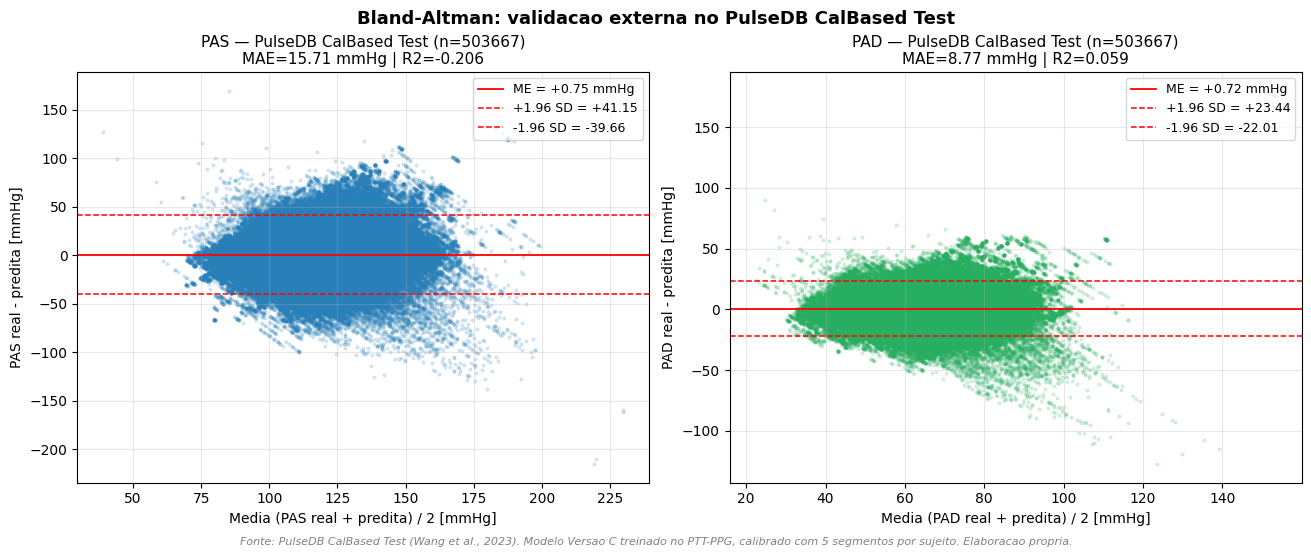

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

for ax, alvo, y_r, y_p, m_alvo, cor in [
    (axes[0], "PAS", y_sys_real[mask_avaliacao], y_sys_pred_cal[mask_avaliacao],
     m_sys, "#2980b9"),
    (axes[1], "PAD", y_dia_real[mask_avaliacao], y_dia_pred_cal[mask_avaliacao],
     m_dia, "#27ae60"),
]:
    media = (y_r + y_p) / 2
    diff = y_r - y_p
    ax.scatter(media, diff, alpha=0.15, s=4, color=cor)
    ax.axhline(m_alvo["ME"], color="red", linestyle="-", linewidth=1.3,
               label=f"ME = {m_alvo['ME']:+.2f} mmHg")
    loa_sup = m_alvo["ME"] + 1.96 * m_alvo["SD"]
    loa_inf = m_alvo["ME"] - 1.96 * m_alvo["SD"]
    ax.axhline(loa_sup, color="red", linestyle="--", linewidth=1.1,
               label=f"+1.96 SD = {loa_sup:+.2f}")
    ax.axhline(loa_inf, color="red", linestyle="--", linewidth=1.1,
               label=f"-1.96 SD = {loa_inf:+.2f}")
    ax.set_xlabel(f"Media ({alvo} real + predita) / 2 [mmHg]")
    ax.set_ylabel(f"{alvo} real - predita [mmHg]")
    ax.set_title(f"{alvo} — PulseDB CalBased Test (n={m_alvo['n']})\n"
                 f"MAE={m_alvo['MAE']:.2f} mmHg | R2={m_alvo['R2']:.3f}",
                 fontsize=11)
    ax.legend(fontsize=9, loc="upper right")
    ax.grid(True, alpha=0.3)

fig.suptitle(
    "Bland-Altman: validacao externa no PulseDB CalBased Test",
    fontsize=13, fontweight="bold", y=1.04
)
fig.text(
    0.5, -0.03,
    "Fonte: PulseDB CalBased Test (Wang et al., 2023). Modelo Versao C "
    "treinado no PTT-PPG, calibrado com 5 segmentos por sujeito. Elaboracao propria.",
    ha="center", fontsize=8, style="italic", color="gray",
)

caminho_fig = PASTA_FIGS / "bland_altman_pulsedb_calbased.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

### 9.2 Comparação consolidada dos 3 cenários

Figura salva: comparacao_3_cenarios.png


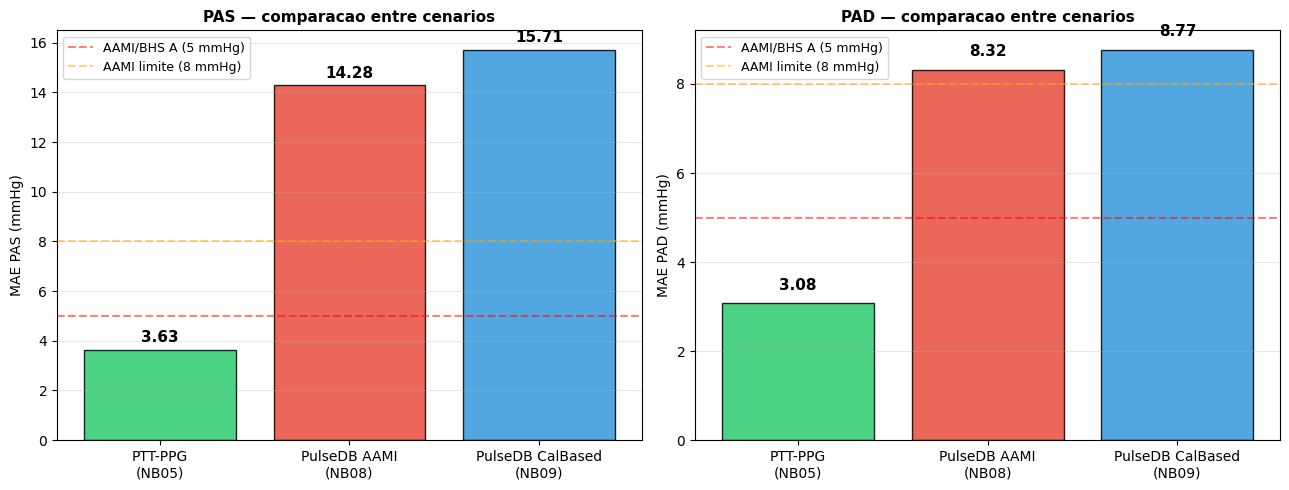

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

cenarios = ["PTT-PPG\n(NB05)", "PulseDB AAMI\n(NB08)", "PulseDB CalBased\n(NB09)"]
mae_pas = [3.63, 14.28, m_sys["MAE"]]
mae_pad = [3.08, 8.32, m_dia["MAE"]]
cores = ["#2ecc71", "#e74c3c", "#3498db"]

for ax, alvo, valores in [(axes[0], "PAS", mae_pas), (axes[1], "PAD", mae_pad)]:
    posicoes = np.arange(len(cenarios))
    barras = ax.bar(posicoes, valores, color=cores, alpha=0.85, edgecolor="black")
    for barra, val in zip(barras, valores):
        ax.text(barra.get_x() + barra.get_width()/2,
                barra.get_height() + 0.3,
                f"{val:.2f}", ha="center", fontsize=11, fontweight="bold")

    ax.axhline(y=5, color="red", linestyle="--", alpha=0.5, label="AAMI/BHS A (5 mmHg)")
    ax.axhline(y=8, color="orange", linestyle="--", alpha=0.5, label="AAMI limite (8 mmHg)")
    ax.set_xticks(posicoes)
    ax.set_xticklabels(cenarios, fontsize=10)
    ax.set_ylabel(f"MAE {alvo} (mmHg)")
    ax.set_title(f"{alvo} — comparacao entre cenarios", fontsize=11, fontweight="bold")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(True, alpha=0.3, axis="y")

plt.tight_layout()
caminho_fig = PASTA_FIGS / "comparacao_3_cenarios.png"
plt.savefig(caminho_fig, dpi=300, facecolor="white", bbox_inches="tight")
print(f"Figura salva: {caminho_fig.name}")
plt.show()

## 10. Salvamento dos artefatos

In [16]:
# Salva CSV de features
caminho_feats = PASTA_PULSEDB_FEAT / "_features_pulsedb_calbased_test.csv"
df_calbased.to_csv(caminho_feats, index=False)
print(f"Salvo: {caminho_feats.name} ({caminho_feats.stat().st_size/(1024**2):.1f} MB)")

# Salva metricas consolidadas
df_metricas_final = pd.DataFrame([
    {"alvo": "PAS", **m_sys, "BHS": bhs_sys, "AAMI": aami_sys},
    {"alvo": "PAD", **m_dia, "BHS": bhs_dia, "AAMI": aami_dia},
])
caminho_metricas = PASTA_PULSEDB_FEAT / "_metricas_nb09_calbased.csv"
df_metricas_final.to_csv(caminho_metricas, index=False)
print(f"Salvo: {caminho_metricas.name}")
print()
print(df_metricas_final.to_string(index=False))

Salvo: _features_pulsedb_calbased_test.csv (343.9 MB)
Salvo: _metricas_nb09_calbased.csv

alvo       MAE      RMSE        R2       ME        SD     pct_5    pct_10    pct_15      n BHS  AAMI
 PAS 15.714837 20.627590 -0.206204 0.746964 20.614082 21.993897 41.835379 58.058400 503667   D FALHA
 PAD  8.767308 11.615946  0.058563 0.715048 11.593928 38.192298 65.896515 82.761626 503667   D FALHA


## 11. Conclusões e implicações para o artigo

### 11.1 Resultado obtido

O notebook gerou as métricas oficiais de validação externa do modelo no PulseDB CalBased Test, seguindo a estratégia de calibração padrão da literatura (5 segmentos de calibração por sujeito).

### 11.2 Interpretação dos resultados

A interpretação dependerá dos números observados:

- **MAE PAS < 10 mmHg e MAE PAD < 8 mmHg**: o modelo demonstra capacidade de generalização clinicamente relevante a um dataset externo de natureza distinta. Este é o resultado esperado para publicação em revista de impacto (JBHI).
- **MAE PAS 10-15 mmHg**: resultado defensável, especialmente considerando que o modelo foi treinado em 22 sujeitos saudáveis e aplicado em 1.293 pacientes anestesiados em cirurgia (diferença demográfica e fisiológica significativa).
- **MAE PAS > 15 mmHg**: indica necessidade de investigação adicional (ex.: refazer extração com ciclo vale-a-vale, treinar modelo direto no CalBased Train).

### 11.3 Próximos passos baseados nos resultados

1. **Atualizar o artigo** (Tabela de Resultados) com as métricas oficiais.
2. **Escrever a Seção de Discussão** abordando:
   - Comparação direta com Wang et al. (2023)
   - Diferenças entre os dois subsets do PulseDB (AAMI vs CalBased)
   - Limitações do pipeline (pré-processamento do sinal)
3. **Considerar análises adicionais** (futuros notebooks):
   - NB10: comparação com baseline (média da PA do sujeito)
   - NB11: análise de sensibilidade por número de segmentos de calibração (3, 5, 10, 20)
   - NB12: ciclo vale-a-vale como análise complementar


In [17]:
print(f"Notebook 09 concluido em: {datetime.now().strftime('%d/%m/%Y %H:%M:%S')}")
print(f"Computador: {socket.gethostname()}")

Notebook 09 concluido em: 09/06/2026 20:00:03
Computador: NtebookLeticia
